<a href="https://colab.research.google.com/github/EMADUDDINAsdaq/bird-species-classification/blob/main/notebook/Fine_Grained_Bird_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CSC8637 Deep Learning Coursework – Task 1: Fine-Grained Bird Classification using Transfer Learning and Custom CNN

In [ ]:
# 0.0 Reproducibility

import os
import random
import numpy as np
import tensorflow as tf
# Ensure reproducibility across runs
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# 0.1 Mount + Extract Dataset

from google.colab import drive
drive.mount("/content/drive")

!cp /content/drive/MyDrive/deep_learning/COURSEWORK/bird_CUB_200_2011.zip /content/
!unzip -q bird_CUB_200_2011.zip
# Check structure
!ls /content/CUB_200_2011

Mounted at /content/drive
attributes	    image_class_labels.txt  parts
bounding_boxes.txt  images		    README
classes.txt	    images.txt		    train_test_split.txt


In [ ]:
# 0.2 Cropping with Margin + Padding

import pandas as pd
from PIL import Image
from tqdm import tqdm

ORIGINAL_BASE = "/content/CUB_200_2011"
CROPPED_BASE  = "/content/CUB_200_2011_CROPPED"

margin = 0.15 #15 % margin to protect context
os.makedirs(os.path.join(CROPPED_BASE, "images"), exist_ok=True)

bbox_df = pd.read_csv(
    os.path.join(ORIGINAL_BASE, "bounding_boxes.txt"),
    sep=" ",
    header=None,
    names=["image_id", "x", "y", "width", "height"]
)

images_df = pd.read_csv(
    os.path.join(ORIGINAL_BASE, "images.txt"),
    sep=" ",
    header=None,
    names=["image_id", "file_path"]
)

crop_df = images_df.merge(bbox_df, on="image_id")

for _, row in tqdm(crop_df.iterrows(), total=len(crop_df)):
    original_path = os.path.join(ORIGINAL_BASE, "images", row["file_path"])
    cropped_path  = os.path.join(CROPPED_BASE, "images", row["file_path"])
    os.makedirs(os.path.dirname(cropped_path), exist_ok=True)

    with Image.open(original_path) as img:
        img_width, img_height = img.size
        x, y = int(row["x"]), int(row["y"])
        w, h = int(row["width"]), int(row["height"])

        x_new = max(0, int(x - margin * w))
        y_new = max(0, int(y - margin * h))
        w_new = int(w * (1 + 2 * margin))
        h_new = int(h * (1 + 2 * margin))

        x2 = min(img_width, x_new + w_new)
        y2 = min(img_height, y_new + h_new)

        cropped = img.crop((x_new, y_new, x2, y2))

        # Pad to square to avoid aspect ratio distortion
        width, height = cropped.size
        max_side = max(width, height)
        padded = Image.new("RGB", (max_side, max_side), (0, 0, 0))
        padded.paste(cropped, ((max_side - width)//2,
                               (max_side - height)//2))

        padded.save(cropped_path)

print("Cropping complete.")

100%|██████████| 11788/11788 [00:37<00:00, 314.69it/s]

Cropping complete.


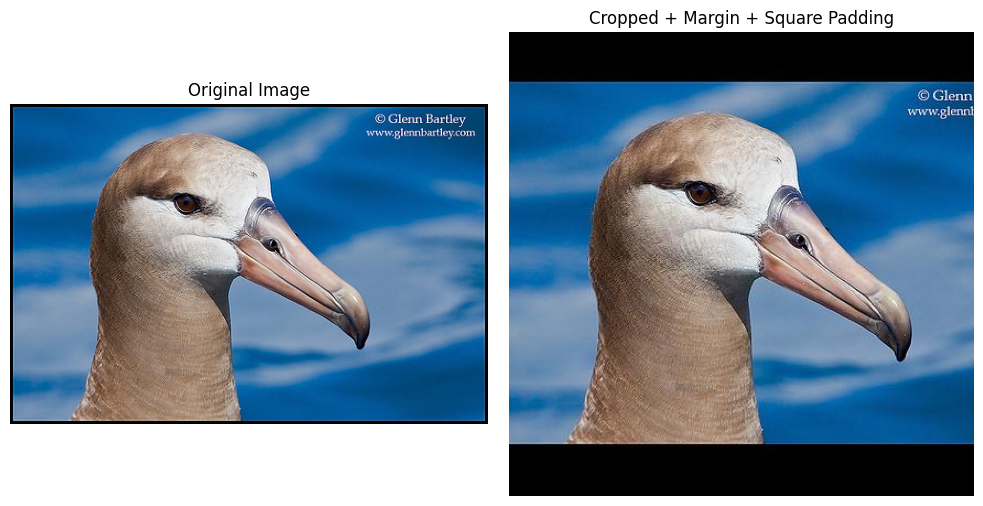

In [ ]:
# Visual Verification of Preprocessing

import matplotlib.pyplot as plt
from PIL import Image
import os

# Select one sample image
sample_row = crop_df.iloc[0]

original_path = os.path.join(ORIGINAL_BASE, "images", sample_row["file_path"])
cropped_path  = os.path.join(CROPPED_BASE, "images", sample_row["file_path"])

original_img = Image.open(original_path)
cropped_img  = Image.open(cropped_path)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(original_img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cropped_img)
plt.title("Cropped + Margin + Square Padding")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 0.3 Train / Validation / Test Split

labels_df = pd.read_csv(
    os.path.join(ORIGINAL_BASE, "image_class_labels.txt"),
    sep=" ",
    header=None,
    names=["image_id", "class_id"]
)

split_df = pd.read_csv(
    os.path.join(ORIGINAL_BASE, "train_test_split.txt"),
    sep=" ",
    header=None,
    names=["image_id", "is_training"]
)

data_df = images_df.merge(labels_df, on="image_id")
data_df = data_df.merge(split_df, on="image_id")

data_df["full_path"] = data_df["file_path"].apply(
    lambda x: os.path.join(CROPPED_BASE, "images", x)
)

train_df = data_df[data_df["is_training"] == 1].copy()
test_df  = data_df[data_df["is_training"] == 0].copy()

train_df["class_id"] = train_df["class_id"].astype(str)
test_df["class_id"]  = test_df["class_id"].astype(str)

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    stratify=train_df["class_id"],
    random_state=42
)

print(train_df.shape, val_df.shape, test_df.shape)

(5394, 5) (600, 5) (5794, 5)


In [ ]:
print(train_df["full_path"].iloc[0])
print(os.path.exists(train_df["full_path"].iloc[0]))

/content/CUB_200_2011_CROPPED/images/167.Hooded_Warbler/Hooded_Warbler_0087_164833.jpg
True


In [ ]:
#Utility function to visualise accuracy and loss
import matplotlib.pyplot as plt

def plot_training_curves(history, title="Model"):

    plt.figure(figsize=(12,5))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='Train')
    plt.plot(history.history['val_accuracy'], label='Validation')
    plt.title(f'{title} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='Train')
    plt.plot(history.history['val_loss'], label='Validation')
    plt.title(f'{title} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

SECTION 1.1 — TRANSFER LEARNING MODEL

In [ ]:
# SECTION 1.1 — EfficientNetB4

#using EffecientNetB4 Transfer Leraning model
# Phase 1: Train classification head only
# Phase 2: Fine-tune upper convolutional layers
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tf.keras.backend.clear_session()

In [ ]:
# Generators for Model 1

IMG_SIZE_1 = 380
BATCH_SIZE_1 = 16
#moderate augmentation to improve generalisation
train_gen_1 = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.15,
    height_shift_range=0.15,
    brightness_range=[0.8, 1.2],
    shear_range=0.1
)


val_gen_1 = ImageDataGenerator(preprocessing_function=preprocess_input)
test_gen_1 = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator_1 = train_gen_1.flow_from_dataframe(
    train_df,
    x_col="full_path",
    y_col="class_id",
    target_size=(IMG_SIZE_1, IMG_SIZE_1),
    class_mode="categorical",
    batch_size=BATCH_SIZE_1
)

val_generator_1 = val_gen_1.flow_from_dataframe(
    val_df,
    x_col="full_path",
    y_col="class_id",
    target_size=(IMG_SIZE_1, IMG_SIZE_1),
    class_mode="categorical",
    batch_size=BATCH_SIZE_1
)

test_generator_1 = test_gen_1.flow_from_dataframe(
    test_df,
    x_col="full_path",
    y_col="class_id",
    target_size=(IMG_SIZE_1, IMG_SIZE_1),
    class_mode="categorical",
    batch_size=BATCH_SIZE_1,
    shuffle=False
)

Found 5394 validated image filenames belonging to 200 classes.
Found 600 validated image filenames belonging to 200 classes.
Found 5794 validated image filenames belonging to 200 classes.


In [ ]:
# Build Model with frozen backbone

base_model = EfficientNetB4(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE_1, IMG_SIZE_1, 3)
)

base_model.trainable = False

model_1 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),  # Reduces parameters
    layers.BatchNormalization(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5), #increased to reduce overfitting
    layers.Dense(200, activation="softmax")
])


71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
model_1.compile(
    optimizer=Adam(3e-4),
    loss=CategoricalCrossentropy(label_smoothing=0.5),
    metrics=["accuracy"]
)

model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb4 (Functional)     │ (None, 12, 12, 1792)   │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1792)           │         7,168 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       918,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │       102,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,701,607 (71.34 MB)

 Trainable params: 1,024,200 (3.91 MB)

 Non-trainable params: 17,677,407 (67.43 MB)

In [ ]:
# Train Phase 1
save_path_1 = "/content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_1.keras"
save_path_1_ft = "/content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_1_ft.keras"
# Update ModelCheckpoint in callbacks to use save_path_1_ft
callbacks_phase1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        save_path_1,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]



In [ ]:
history_1 = model_1.fit(
    train_generator_1,
    validation_data=val_generator_1,
    epochs=20,
    callbacks=callbacks_phase1
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 0s 629ms/step - accuracy: 0.0963 - loss: 5.5275
Epoch 1: val_accuracy improved from -inf to 0.57000, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_1.keras
338/338 ━━━━━━━━━━━━━━━━━━━━ 313s 763ms/step - accuracy: 0.0965 - loss: 5.5264 - val_accuracy: 0.5700 - val_loss: 4.3288 - learning_rate: 3.0000e-04
Epoch 2/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 0s 548ms/step - accuracy: 0.4334 - loss: 4.5665
Epoch 2: val_accuracy improved from 0.57000 to 0.67500, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_1.keras
338/338 ━━━━━━━━━━━━━━━━━━━━ 190s 561ms/step - accuracy: 0.4335 - loss: 4.5665 - val_accuracy: 0.6750 - val_loss: 4.0725 - learning_rate: 3.0000e-04
Epoch 3/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 0s 543ms/step - accuracy: 0.5467 - loss: 4.3738
Epoch 3: val_accuracy improved from 0.67500 to 0.75333, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model

In [ ]:
callbacks_finetune = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=4,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        save_path_1_ft,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
# Fine-tuning: unfreeze last 60 layers
base_model.trainable = True
for layer in base_model.layers[:-60]:
    layer.trainable = False
# BatchNorm layers remain frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
# Lower learning rate
model_1.compile(
    optimizer=Adam(learning_rate=1e-5,
                   clipnorm=1.0
    ),
    loss=CategoricalCrossentropy(label_smoothing=0.05),
    metrics=["accuracy"]
)

history_ft_1 = model_1.fit(
    train_generator_1,
    validation_data=val_generator_1,
    epochs=20,
    callbacks=callbacks_finetune
)

Epoch 1/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 0s 613ms/step - accuracy: 0.9384 - loss: 1.4307
Epoch 1: val_accuracy improved from -inf to 0.81500, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_1_ft.keras
338/338 ━━━━━━━━━━━━━━━━━━━━ 292s 709ms/step - accuracy: 0.9384 - loss: 1.4303 - val_accuracy: 0.8150 - val_loss: 1.2904 - learning_rate: 1.0000e-05
Epoch 2/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 0s 554ms/step - accuracy: 0.9251 - loss: 1.0971
Epoch 2: val_accuracy improved from 0.81500 to 0.81833, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_1_ft.keras
338/338 ━━━━━━━━━━━━━━━━━━━━ 192s 567ms/step - accuracy: 0.9251 - loss: 1.0970 - val_accuracy: 0.8183 - val_loss: 1.1678 - learning_rate: 1.0000e-05
Epoch 3/20
338/338 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.9194 - loss: 0.9863
Epoch 3: val_accuracy improved from 0.81833 to 0.82333, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Load fine-tuned model
model_1 = tf.keras.models.load_model(save_path_1_ft)

test_loss_1, test_acc_1 = model_1.evaluate(test_generator_1, verbose=0)

y_pred = model_1.predict(test_generator_1, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_generator_1.classes

report = classification_report(y_true, y_pred_classes, output_dict=True)

print("===== Task 1.1 — EfficientNetB4 Results =====")
print(f"Test Accuracy : {test_acc_1:.4f}")
print(f"Macro Precision: {report['macro avg']['precision']:.4f}")
print(f"Macro Recall   : {report['macro avg']['recall']:.4f}")
print(f"Macro F1       : {report['macro avg']['f1-score']:.4f}")

===== Task 1.1 — EfficientNetB4 Results =====
Test Accuracy : 0.8421
Macro Precision: 0.8484
Macro Recall   : 0.8433
Macro F1       : 0.8416


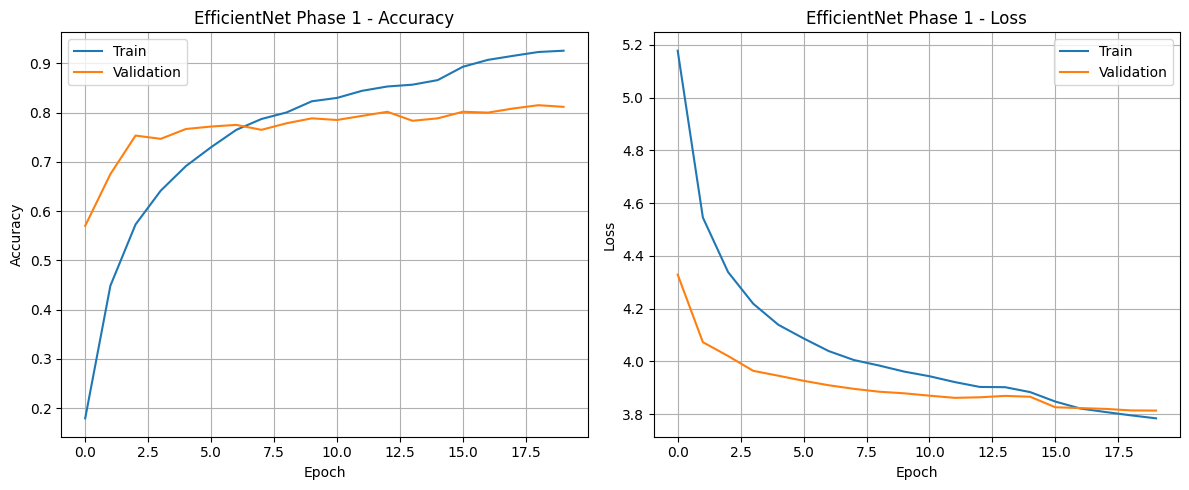

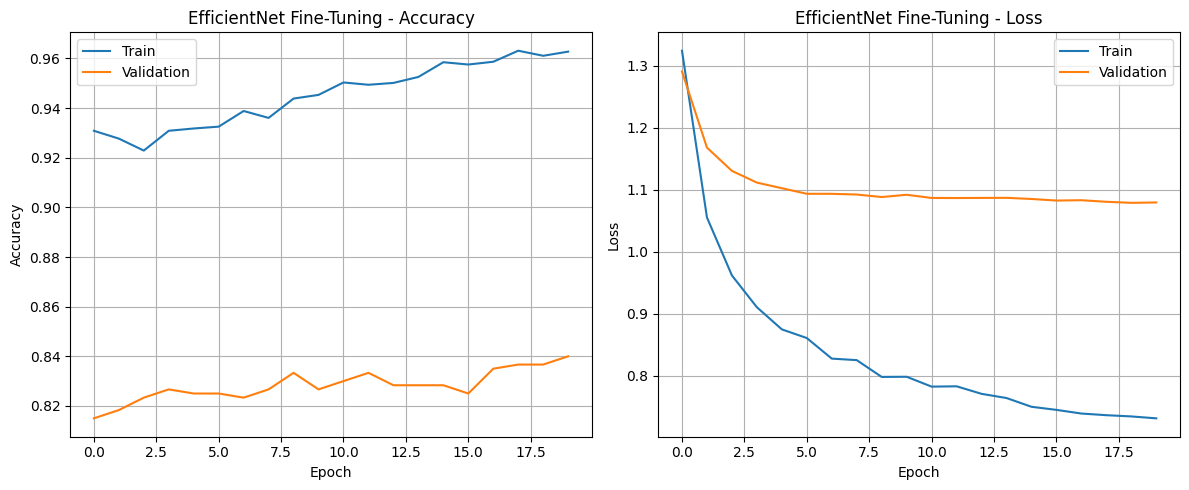

In [ ]:
plot_training_curves(history_1, "EfficientNet Phase 1")
plot_training_curves(history_ft_1, "EfficientNet Fine-Tuning")

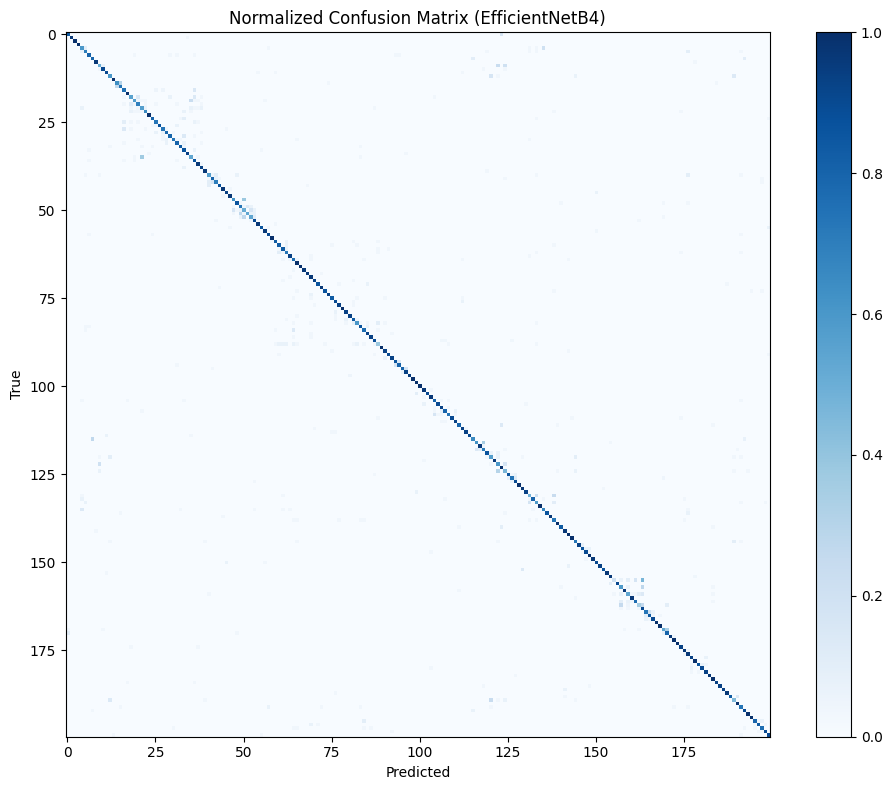

In [ ]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Load predictions from
y_pred_probs = model_1.predict(test_generator_1, verbose=0)
y_pred_eff = np.argmax(y_pred_probs, axis=1)
y_true_eff = test_generator_1.classes

cm_eff = confusion_matrix(y_true_eff, y_pred_eff, normalize='true')

plt.figure(figsize=(10,8))
plt.imshow(cm_eff, interpolation='nearest', cmap='Blues')
plt.title("Normalized Confusion Matrix (EfficientNetB4)")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

SECTION 1.2 — CUSTOM CNN MODEL

In [ ]:
tf.keras.backend.clear_session()

In [ ]:
# SECTION 1.2 — Custom CNN
# Custom CNN built from scratch
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

IMG_SIZE_2 = 224
BATCH_SIZE_2 = 32

In [ ]:
# Moderate augmentation to improve generalisation.
train_gen_2 = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    brightness_range=[0.9, 1.1]
)

val_gen_2 = ImageDataGenerator(rescale=1./255)
test_gen_2 = ImageDataGenerator(rescale=1./255)

train_generator_2 = train_gen_2.flow_from_dataframe(
    train_df,
    x_col="full_path",
    y_col="class_id",
    target_size=(IMG_SIZE_2, IMG_SIZE_2),
    class_mode="categorical",
    batch_size=BATCH_SIZE_2
)

val_generator_2 = val_gen_2.flow_from_dataframe(
    val_df,
    x_col="full_path",
    y_col="class_id",
    target_size=(IMG_SIZE_2, IMG_SIZE_2),
    class_mode="categorical",
    batch_size=BATCH_SIZE_2,
    shuffle=False
)

test_generator_2 = test_gen_2.flow_from_dataframe(
    test_df,
    x_col="full_path",
    y_col="class_id",
    target_size=(IMG_SIZE_2, IMG_SIZE_2),
    class_mode="categorical",
    batch_size=BATCH_SIZE_2,
    shuffle=False
)

Found 5394 validated image filenames belonging to 200 classes.
Found 600 validated image filenames belonging to 200 classes.
Found 5794 validated image filenames belonging to 200 classes.


In [ ]:
# Custom CNN Architecture

def create_model():

    model = Sequential()

    # Stage 1  --low level feature extraction  edged , textures
    model.add(Conv2D(64, (3,3), padding='same',
                     kernel_initializer='he_normal',
                     input_shape=(IMG_SIZE_2, IMG_SIZE_2, 3)))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    model.add(Conv2D(64, (3,3),
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    # Stage 2 --# Increase depth and downsample
    model.add(Conv2D(128, (3,3), strides=2,
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    model.add(Conv2D(128, (3,3),
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    # Stage 3
    model.add(Conv2D(256, (3,3), strides=2,
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    model.add(Conv2D(256, (3,3),
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    # Stage 4 High-level semantic features
    model.add(Conv2D(512, (3,3), strides=2,
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    model.add(Conv2D(512, (3,3),
                     kernel_initializer='he_normal',
                     padding='same'))
    model.add(BatchNormalization())
    model.add(Activation('relu'))

    # Classification Head
    model.add(GlobalAveragePooling2D()) #educes overfitting
    model.add(Dense(512, activation='relu'))
    model.add(Dropout(0.4)) # Dropout helps reduce overfitting
    model.add(Dense(200, activation='softmax'))

    model.compile(
        optimizer=Adam(learning_rate=3e-4),
        loss=CategoricalCrossentropy(),
        metrics=['accuracy']
    )

    return model
# Progressive depth increase (64 → 512 filters)
# Strided convolutions used for downsampling
# Dropout used for regularisation

model_2 = create_model()
model_2.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 28, 28, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 5,058,312 (19.30 MB)

 Trainable params: 5,054,472 (19.28 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [ ]:
#  Callbacks
save_path_2 = "/content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_2.keras"
callbacks_2 = [
    # Reduces learning rate when validation loss stops improving.
    ReduceLROnPlateau(
        monitor='val_loss',
        patience=6,
        factor=0.3,
        verbose=1
    ),
    EarlyStopping(
        # Prevents excessive overfitting by stopping training early.
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        # Saves best-performing model on validation set.
        save_path_2,
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

In [ ]:
# -------- Training --------

history_2 = model_2.fit(
    train_generator_2,
    validation_data=val_generator_2,
    epochs=50,
    callbacks=callbacks_2
)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 611ms/step - accuracy: 0.0117 - loss: 5.3272
Epoch 1: val_accuracy improved from -inf to 0.01000, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_2.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 151s 717ms/step - accuracy: 0.0117 - loss: 5.3267 - val_accuracy: 0.0100 - val_loss: 5.3089 - learning_rate: 3.0000e-04
Epoch 2/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.0188 - loss: 5.0869
Epoch 2: val_accuracy improved from 0.01000 to 0.01833, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_task1_2.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 70s 413ms/step - accuracy: 0.0188 - loss: 5.0869 - val_accuracy: 0.0183 - val_loss: 5.1320 - learning_rate: 3.0000e-04
Epoch 3/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.0293 - loss: 4.9444
Epoch 3: val_accuracy improved from 0.01833 to 0.03667, saving model to /content/drive/MyDrive/deep_learning/COURSEWORK/task1_model/model_

In [ ]:
# Load Best Model
import tensorflow as tf

model_2 = tf.keras.models.load_model(save_path_2)
print("Best Custom CNN model loaded successfully.")

Best Custom CNN model loaded successfully.


In [ ]:
# CELL 2 — Compute Metrics
from sklearn.metrics import f1_score
import numpy as np

# Evaluate silently
test_loss_2, test_acc_2 = model_2.evaluate(test_generator_2, verbose=0)

# Predictions
y_pred_probs = model_2.predict(test_generator_2, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator_2.classes

# F1 Scores
macro_f1 = f1_score(y_true, y_pred, average='macro')
weighted_f1 = f1_score(y_true, y_pred, average='weighted')

print("===== Task 1.2 — Custom CNN Results =====")
print(f"Test Accuracy : {test_acc_2:.4f}")
print(f"Macro F1      : {macro_f1:.4f}")
print(f"Weighted F1   : {weighted_f1:.4f}")

===== Task 1.2 — Custom CNN Results =====
Test Accuracy : 0.2761
Macro F1      : 0.2675
Weighted F1   : 0.2671


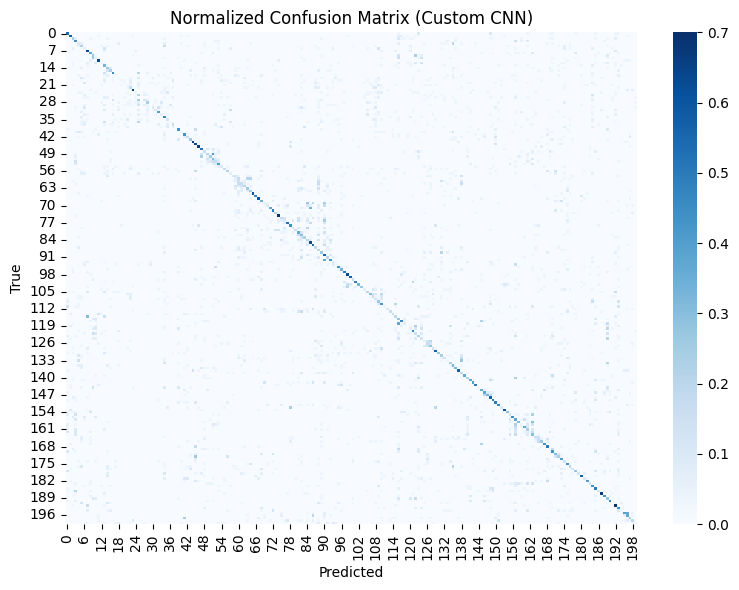

In [ ]:
#  Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, normalize='true')

plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap="Blues", cbar=True)
plt.title("Normalized Confusion Matrix (Custom CNN)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

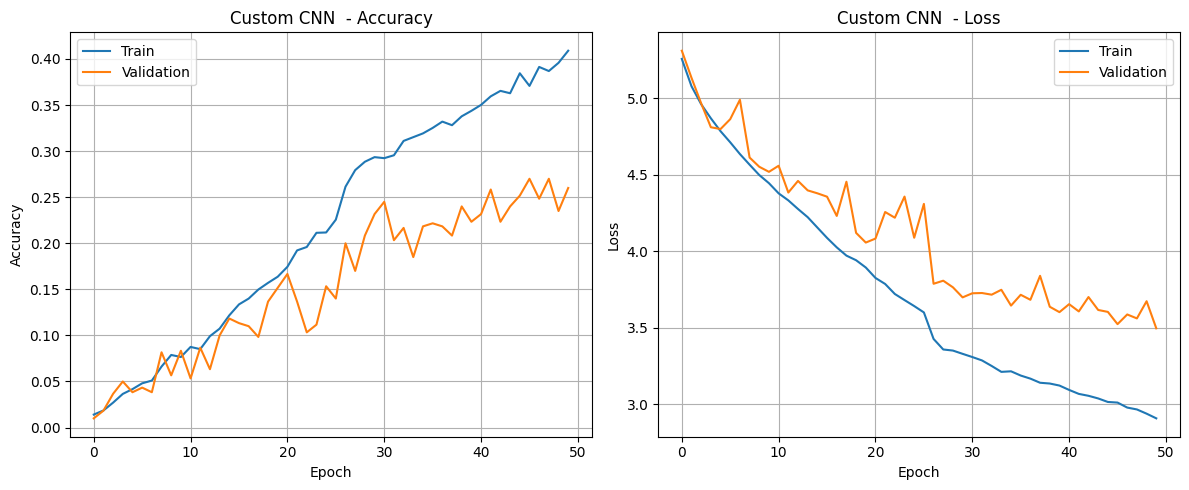

In [ ]:
#  Training Curves
plot_training_curves(history_2, "Custom CNN ")

In [ ]:
# Compare final test accuracies of both models

models = ['EfficientNetB4', 'Custom CNN']
accuracies = [test_acc_1, test_acc_2]

plt.figure(figsize=(6,5))
plt.bar(models, accuracies)
plt.ylabel("Test Accuracy")
plt.title("Model Comparison")
plt.ylim(0,1)
plt.show()

###I. Introduction

This study investigates fine-grained bird classification on the CUB-200-2011 dataset [1] using two approaches: transfer learning with EfficientNet and a custom convolutional neural network (CNN) trained from scratch. The objective was to evaluate how model capacity and training strategy influence generalisation performance on a dataset containing 200 visually similar bird species.

###II. Dataset Preprocessing

Initial experiments using the original uncropped images resulted in lower validation accuracy, primarily due to background clutter and inconsistent object scale. Since the dataset provides bounding box annotations [1], these were used to crop each bird instance to improve object focus. A 15% margin was added around each bounding box to preserve discriminative contextual cues such as wing edges and plumage patterns, which are essential for distinguishing similar species.

Following cropping, images were padded to square format prior to resizing. This prevented geometric distortion and ensured consistent spatial dimensions across samples. In practice, this preprocessing pipeline improved convergence stability and increased validation accuracy compared to training on the original images.

###III. Transfer Learning with EfficientNet

EfficientNetB0 [2] was initially evaluated; however, validation performance plateaued early. Replacing it with EfficientNetB4 [2] resulted in consistent improvement, indicating that the increased representational capacity better captured subtle inter-class differences across 200 fine-grained categories.

Earlier configurations achieved approximately 80% validation accuracy but exhibited noticeable overfitting, with training accuracy approaching 95%. To improve generalisation, dropout was increased (0.4 → 0.5), the fine-tuning learning rate was reduced (3×10⁻⁴ → 1×10⁻⁵), and the top 60 layers were unfrozen while Batch Normalisation layers remained frozen for stability. These refinements improved performance, achieving a test accuracy of 84.21%, with balanced macro precision (0.8484), recall (0.8433), and F1-score (0.8416).

###IV. Custom CNN (Training from Scratch)

A custom convolutional neural network was implemented as a controlled baseline and trained from scratch using four progressive convolutional stages (64–512 filters) with Batch Normalisation, ReLU activations, strided downsampling, and Global Average Pooling, followed by a dropout-regularised classification head. Moderate augmentation and learning rate scheduling (initial 3×10⁻⁴, reduced on plateau) were applied. In earlier experiments using uncropped images, the model achieved higher training accuracy but very low test performance (~30%), indicating strong memorisation and overfitting due to background bias. After introducing bounding-box cropping with margin and consistent preprocessing, optimisation became more stable; however, the final model reached 27.61% test accuracy (macro F1 ≈ 0.27), with training accuracy ~41% and validation peaking at 27%. Despite architectural tuning and regularisation, the limited dataset size and absence of pretraining constrained feature learning, reinforcing the superiority of the EfficientNetB4 transfer learning approach for this fine-grained task.

###References

[1] C. Wah, S. Branson, P. Welinder, P. Perona, and S. Belongie, The Caltech-UCSD Birds-200-2011 Dataset, California Institute of Technology, 2011.

[2] M. Tan and Q. Le, “EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks,” in Proceedings of the 36th International Conference on Machine Learning (ICML), 2019.